<a href="https://colab.research.google.com/github/harsha-vardhann-reddy/Deep-Learning-Session/blob/main/Week_9_DLAC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using device: cpu
No GPU detected. The model will run on CPU.
For GPU results, choose Runtime > Change runtime type > GPU.


100%|██████████| 9.91M/9.91M [00:00<00:00, 43.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.16MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.96MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.84MB/s]


Epoch 1/2 — loss: 1.0470
Epoch 2/2 — loss: 0.3519

========== INFERENCE BASELINE RESULTS ==========


,Metric,Result
0,Accuracy,88.10%
1,Classification mAP (one-vs-rest),94.94%
2,Single-image latency (median),0.139 ms
3,Single-image latency (95th percentile),0.184 ms
4,Batched throughput (batch size 64),9292.88 images/second
5,Peak GPU memory allocated,GPU unavailable
6,Peak GPU memory reserved,GPU unavailable


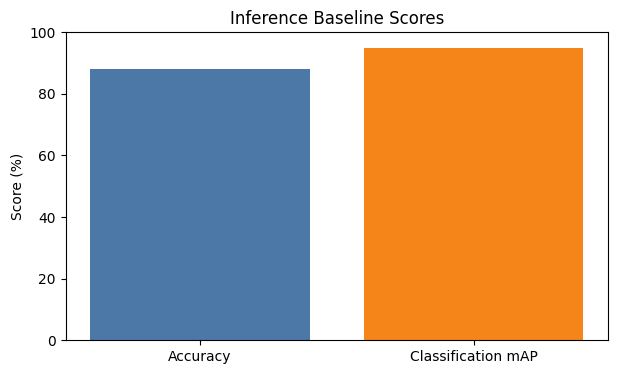

INFERENCE BASELINE COMPLETED!


In [1]:
# INFERENCE BASELINE
# Accuracy | Classification mAP | Single-image latency
# Batched throughput | GPU memory

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
from IPython.display import display

# 1. Choose GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. The model will run on CPU.")
    print("For GPU results, choose Runtime > Change runtime type > GPU.")

def sync_device():
    if device.type == "cuda":
        torch.cuda.synchronize()

# 2. Define the classifier
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(1, 16, kernel_size=3)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2)
        self.fc = nn.Linear(16 * 13 * 13, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv(x)))
        x = x.flatten(1)
        return self.fc(x)

model = CNN().to(device)

# 3. Load a small MNIST training sample
transform = transforms.ToTensor()

train_full = torchvision.datasets.MNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=transform,
)
train_data = Subset(train_full, range(5000))
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

# 4. Train the model briefly
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(2):
    model.train()
    total_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch + 1}/2 — loss: {total_loss / len(train_loader):.4f}")

# 5. Load test images
test_full = torchvision.datasets.MNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform,
)
test_data = Subset(test_full, range(2000))
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

# 6. Measure accuracy and collect class probabilities
model.eval()
probability_batches = []
label_batches = []

with torch.inference_mode():
    for images, labels in test_loader:
        logits = model(images.to(device))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()

        probability_batches.append(probabilities)
        label_batches.append(labels.numpy())

all_probabilities = np.concatenate(probability_batches)
all_labels = np.concatenate(label_batches)
predicted_labels = np.argmax(all_probabilities, axis=1)

accuracy = float(np.mean(predicted_labels == all_labels))

# 7. Calculate classification mAP
# AP is calculated for each digit class; mAP is their mean.
average_precisions = []

for class_id in range(10):
    binary_labels = (all_labels == class_id).astype(np.int32)
    class_scores = all_probabilities[:, class_id]

    if binary_labels.sum() == 0:
        continue

    sorted_indices = np.argsort(-class_scores)
    sorted_labels = binary_labels[sorted_indices]
    true_positives = np.cumsum(sorted_labels)
    ranks = np.arange(1, len(sorted_labels) + 1)
    precision_at_rank = true_positives / ranks

    average_precision = precision_at_rank[sorted_labels == 1].mean()
    average_precisions.append(average_precision)

mean_average_precision = float(np.mean(average_precisions))

# 8. Measure single-image latency
# Includes CPU-to-device transfer, model inference, and returning the output to CPU.
single_image, _ = test_data[0]
single_image = single_image.unsqueeze(0)

with torch.inference_mode():
    for _ in range(10):
        output = model(single_image.to(device))
        _ = output.cpu()

sync_device()
single_image_times_ms = []

for _ in range(100):
    sync_device()
    start = time.perf_counter()

    with torch.inference_mode():
        output = model(single_image.to(device))
        _ = output.cpu()

    sync_device()
    single_image_times_ms.append((time.perf_counter() - start) * 1000)

latency_p50_ms = float(np.percentile(single_image_times_ms, 50))
latency_p95_ms = float(np.percentile(single_image_times_ms, 95))

# 9. Measure batched throughput
# Includes input transfer, model inference, and output transfer.
batch_size = 64
number_of_iterations = 30
cpu_batch = torch.stack([test_data[i][0] for i in range(batch_size)])

with torch.inference_mode():
    for _ in range(5):
        warmup_output = model(cpu_batch.to(device))
        _ = warmup_output.cpu()

sync_device()

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats(device)

sync_device()
start = time.perf_counter()

with torch.inference_mode():
    for _ in range(number_of_iterations):
        batch_on_device = cpu_batch.to(device)
        batch_output = model(batch_on_device)
        _ = batch_output.cpu()

sync_device()
elapsed_seconds = time.perf_counter() - start

total_benchmarked_images = batch_size * number_of_iterations
throughput = total_benchmarked_images / elapsed_seconds

# 10. Measure peak GPU memory
if device.type == "cuda":
    peak_allocated_mb = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    peak_reserved_mb = torch.cuda.max_memory_reserved(device) / (1024 ** 2)
else:
    peak_allocated_mb = None
    peak_reserved_mb = None

# 11. Display all results in Colab
results = pd.DataFrame([
    {"Metric": "Accuracy", "Result": f"{accuracy * 100:.2f}%"},
    {
        "Metric": "Classification mAP (one-vs-rest)",
        "Result": f"{mean_average_precision * 100:.2f}%",
    },
    {"Metric": "Single-image latency (median)", "Result": f"{latency_p50_ms:.3f} ms"},
    {"Metric": "Single-image latency (95th percentile)", "Result": f"{latency_p95_ms:.3f} ms"},
    {
        "Metric": f"Batched throughput (batch size {batch_size})",
        "Result": f"{throughput:.2f} images/second",
    },
    {
        "Metric": "Peak GPU memory allocated",
        "Result": f"{peak_allocated_mb:.2f} MB" if peak_allocated_mb is not None else "GPU unavailable",
    },
    {
        "Metric": "Peak GPU memory reserved",
        "Result": f"{peak_reserved_mb:.2f} MB" if peak_reserved_mb is not None else "GPU unavailable",
    },
])

print("\n========== INFERENCE BASELINE RESULTS ==========")
display(results)

# 12. Show score chart
plt.figure(figsize=(7, 4))
plt.bar(
    ["Accuracy", "Classification mAP"],
    [accuracy * 100, mean_average_precision * 100],
    color=["#4C78A8", "#F58518"],
)
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.title("Inference Baseline Scores")
plt.show()

print("INFERENCE BASELINE COMPLETED!")